# U-Net Subtract-One-Out Ablation Study
## IAN Canal & M3M Segmentation — AMD DirectML Version

**Design:** One full model with all 3 components active, then remove one component at a time.  
Results are directly comparable to the isolate-one-only study (same 512×512, 50 epochs, ResNet-50 + ImageNet).

**Full model (all ON):** Surgical CLAHE · Dice+BCE Loss · Full Augmentation · ResNet-50 ImageNet

| Run | Preprocessing | Loss (IAN/M3M dice_weight) | Augmentation |
|-----|--------------|----------------------------|--------------|
| Full | ✅ Surgical CLAHE | ✅ 0.6 / 0.4 | ✅ Full pipeline |
| Remove Preprocessing | ❌ Raw image | ✅ 0.6 / 0.4 | ✅ Full pipeline |
| Remove Loss | ✅ Surgical CLAHE | ❌ Pure BCE (0.0) | ✅ Full pipeline |
| Remove Augmentation | ✅ Surgical CLAHE | ✅ 0.6 / 0.4 | ❌ Normalize only |

The drop from Full to each "Remove" run quantifies how much each component contributes  
when the other two are present.


## 1. Imports

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch_directml
DEVICE = torch_directml.device()

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)
print(f'✓ Device: {DEVICE}')


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Device: privateuseone:0


## 2. Configuration
⚠️ Update the three path constants below.

In [2]:
# ── UPDATE THESE ──────────────────────────────────────────────────────────────
COCO_JSON_PATH = r'E:\IIT\NEW_FYP\DATASETS\FINAL\batch1-20.json'
IMAGE_DIR      = r'E:\IIT\NEW_FYP\DATASETS\FINAL'
ABLATION_DIR   = r'E:\IIT\NEW_FYP\MODELS\Ablation_Subtract_One_Out'
# ─────────────────────────────────────────────────────────────────────────────

os.makedirs(ABLATION_DIR, exist_ok=True)

IMG_SIZE    = 1024
BATCH_SIZE  = 2
EPOCHS      = 30
LR          = 1e-4
LR_MIN      = 1e-6
SPLIT_SEED  = 42
TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15

CANAL_STRIP_TOP    = 0.57
CANAL_STRIP_BOTTOM = 0.90
CANAL_BLEND_PAD    = 0.04

BASELINE_ENCODER    = 'resnet50'
BASELINE_PRETRAINED = 'imagenet'

print(f'IMG_SIZE={IMG_SIZE}  BATCH={BATCH_SIZE}  EPOCHS={EPOCHS}')
print(f'Encoder : {BASELINE_ENCODER} + {BASELINE_PRETRAINED}')
print(f'Outputs : {ABLATION_DIR}')


IMG_SIZE=1024  BATCH=2  EPOCHS=30
Encoder : resnet50 + imagenet
Outputs : E:\IIT\NEW_FYP\MODELS\Ablation_Subtract_One_Out


## 3. Component Definitions

In [3]:
# ── Preprocessing ─────────────────────────────────────────────────────────────

def get_strip_mask(h, w, top_frac, bot_frac, pad_frac):
    mask   = np.zeros(h, dtype=np.float32)
    top_px = int(h * top_frac); bot_px = int(h * bot_frac)
    pad_px = max(1, int(h * pad_frac))
    for i in range(pad_px):
        r = top_px - pad_px + i
        if 0 <= r < h: mask[r] = i / pad_px
    mask[top_px:bot_px] = 1.0
    for i in range(pad_px):
        r = bot_px + i
        if 0 <= r < h: mask[r] = 1.0 - (i / pad_px)
    return mask[:, np.newaxis].repeat(w, axis=1)

def surgical_clahe_unsharp(img_bgr, clahe_clip=2.5, clahe_tile=(6,6), sigma=1.0, weight=1.2):
    h, w    = img_bgr.shape[:2]
    lab     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    clahe   = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=clahe_tile)
    L_c     = clahe.apply(L)
    blurred = cv2.GaussianBlur(L_c, (0,0), sigmaX=sigma)
    L_sharp = np.clip(cv2.addWeighted(L_c, weight, blurred, -(weight-1.0), 0), 0, 255).astype(np.uint8)
    mask    = get_strip_mask(h, w, CANAL_STRIP_TOP, CANAL_STRIP_BOTTOM, CANAL_BLEND_PAD)
    L_blend = np.clip(L.astype(np.float32)*(1-mask) + L_sharp.astype(np.float32)*mask, 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([L_blend, a, b]), cv2.COLOR_LAB2BGR)

def no_preprocessing(img_bgr):
    return img_bgr

# ── Loss ──────────────────────────────────────────────────────────────────────

class DiceBCELoss(nn.Module):
    def __init__(self, dice_weight=0.6, smooth=1.0):
        super().__init__()
        self.dice_w = dice_weight; self.bce_w = 1.0 - dice_weight
        self.smooth = smooth;      self.bce   = nn.BCEWithLogitsLoss()

    def dice_loss(self, logits, targets):
        probs = torch.sigmoid(logits)
        p = probs.view(probs.size(0), -1); t = targets.view(targets.size(0), -1)
        inter = (p*t).sum(dim=1); denom = p.sum(dim=1) + t.sum(dim=1) + self.smooth
        return 1.0 - (2.0*inter + self.smooth) / denom

    def forward(self, logits, targets):
        if self.dice_w == 0.0:
            return self.bce(logits, targets)
        return self.dice_w * self.dice_loss(logits, targets).mean() + self.bce_w * self.bce(logits, targets)

# ── Encoder ───────────────────────────────────────────────────────────────────

def build_unet():
    return smp.Unet(
        encoder_name=BASELINE_ENCODER, encoder_weights=BASELINE_PRETRAINED,
        in_channels=3, classes=1, activation=None, decoder_use_batchnorm=True,
    )

# ── Augmentation ──────────────────────────────────────────────────────────────

NORM = dict(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

AUGMENTATION_OFF = A.Compose([A.Normalize(**NORM), ToTensorV2()])

AUGMENTATION_ON  = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=5, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.4),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.Normalize(**NORM), ToTensorV2(),
])

VAL_TRANSFORM = AUGMENTATION_OFF

print('✓ All component variants defined')


✓ All component variants defined


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
C:\Users\minud\AppData\Local\Temp\ipykernel_25608\3231987735.py:68: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),


## 4. Ablation Run Configurations

In [4]:
ABLATION_RUNS = [
    {
        'id':         'full',
        'label':      'Full Model (all components ON)',
        'preprocess': surgical_clahe_unsharp,   # ✅
        'ian_dice_w': 0.6,                      # ✅
        'm3m_dice_w': 0.4,                      # ✅
        'train_tfm':  AUGMENTATION_ON,          # ✅
        'removed':    'none',
    },
    {
        'id':         'remove_preprocess',
        'label':      'Remove Preprocessing',
        'preprocess': no_preprocessing,         # ❌ removed
        'ian_dice_w': 0.6,                      # ✅
        'm3m_dice_w': 0.4,                      # ✅
        'train_tfm':  AUGMENTATION_ON,          # ✅
        'removed':    'Preprocessing',
    },
    {
        'id':         'remove_loss',
        'label':      'Remove Loss (→ pure BCE)',
        'preprocess': surgical_clahe_unsharp,   # ✅
        'ian_dice_w': 0.0,                      # ❌ removed → pure BCE
        'm3m_dice_w': 0.0,                      # ❌ removed → pure BCE
        'train_tfm':  AUGMENTATION_ON,          # ✅
        'removed':    'Loss (Dice component)',
    },
    {
        'id':         'remove_augmentation',
        'label':      'Remove Augmentation',
        'preprocess': surgical_clahe_unsharp,   # ✅
        'ian_dice_w': 0.6,                      # ✅
        'm3m_dice_w': 0.4,                      # ✅
        'train_tfm':  AUGMENTATION_OFF,         # ❌ removed
        'removed':    'Augmentation',
    },
]

print('Subtract-one-out runs:')
for cfg in ABLATION_RUNS:
    removed = f'  ← REMOVED: {cfg["removed"]}' if cfg['removed'] != 'none' else '  ← BASELINE'
    print(f"  {cfg['label']}{removed}")


Subtract-one-out runs:
  Full Model (all components ON)  ← BASELINE
  Remove Preprocessing  ← REMOVED: Preprocessing
  Remove Loss (→ pure BCE)  ← REMOVED: Loss (Dice component)
  Remove Augmentation  ← REMOVED: Augmentation


## 5. Load Data & Build Splits

In [5]:
with open(COCO_JSON_PATH, 'r') as f:
    coco_data = json.load(f)

cat_name_to_id = {cat['name']: cat['id'] for cat in coco_data['categories']}
ian_key    = next(k for k in cat_name_to_id if 'IDN' in k or 'canal' in k.lower())
m3m_key    = next(k for k in cat_name_to_id if 'molar' in k.lower() or 'Mandibular' in k)
IAN_CAT_ID = cat_name_to_id[ian_key]
M3M_CAT_ID = cat_name_to_id[m3m_key]
print(f'IAN: "{ian_key}" (id={IAN_CAT_ID})  |  M3M: "{m3m_key}" (id={M3M_CAT_ID})')

img_to_anns = {}
for ann in coco_data['annotations']:
    img_to_anns.setdefault(ann['image_id'], []).append(ann)

matched = [
    img for img in coco_data['images']
    if os.path.exists(os.path.join(IMAGE_DIR, img['file_name'])) and img['id'] in img_to_anns
]
print(f'Matched images: {len(matched)}')

ian_imgs   = [m for m in matched if any(a['category_id']==IAN_CAT_ID for a in img_to_anns[m['id']])]
noian_imgs = [m for m in matched if m not in ian_imgs]
random.seed(SPLIT_SEED)
random.shuffle(ian_imgs); random.shuffle(noian_imgs)

def split_list(lst, tr, vr):
    n = len(lst)
    return lst[:int(n*tr)], lst[int(n*tr):int(n*(tr+vr))], lst[int(n*(tr+vr)):]

ian_tr,   ian_val,   ian_te   = split_list(ian_imgs,   TRAIN_RATIO, VAL_RATIO)
noian_tr, noian_val, noian_te = split_list(noian_imgs, TRAIN_RATIO, VAL_RATIO)
SPLITS = {'train': ian_tr+noian_tr, 'val': ian_val+noian_val, 'test': ian_te+noian_te}

print('\nSplits (seed=42, stratified by IAN):')
for s, imgs in SPLITS.items():
    ian_c = sum(1 for m in imgs if any(a['category_id']==IAN_CAT_ID for a in img_to_anns[m['id']]))
    print(f'  {s:5s}: {len(imgs):3d} images  ({ian_c} with IAN)')


IAN: "IDN canal" (id=2)  |  M3M: "Mandibular Third molar" (id=1)
Matched images: 480

Splits (seed=42, stratified by IAN):
  train: 335 images  (331 with IAN)
  val  :  72 images  (71 with IAN)
  test :  73 images  (72 with IAN)


## 6. Mask Renderer & Dataset

In [6]:
def coco_polygons_to_mask(annotations, cat_id, img_h, img_w, target_size):
    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    for ann in annotations:
        if ann['category_id'] != cat_id: continue
        for seg in ann.get('segmentation', []):
            if len(seg) < 6: continue
            pts = np.array(seg, dtype=np.float32).reshape(-1,2).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    if target_size != img_h or target_size != img_w:
        mask = cv2.resize(mask, (target_size, target_size), interpolation=cv2.INTER_NEAREST)
    return mask.astype(np.float32)


class DentalDataset(Dataset):
    def __init__(self, img_infos, image_dir, img_to_anns,
                 ian_cat_id, m3m_cat_id, transform, preprocess_fn):
        self.img_infos    = img_infos;   self.image_dir   = image_dir
        self.img_to_anns  = img_to_anns; self.ian_cat_id  = ian_cat_id
        self.m3m_cat_id   = m3m_cat_id;  self.transform   = transform
        self.preprocess_fn = preprocess_fn

    def __len__(self): return len(self.img_infos)

    def __getitem__(self, idx):
        info    = self.img_infos[idx]
        img_bgr = cv2.imread(os.path.join(self.image_dir, info['file_name']))
        img_bgr = self.preprocess_fn(img_bgr)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

        anns     = self.img_to_anns.get(info['id'], [])
        h, w     = info['height'], info['width']
        ian_mask = coco_polygons_to_mask(anns, self.ian_cat_id, h, w, IMG_SIZE)
        m3m_mask = coco_polygons_to_mask(anns, self.m3m_cat_id, h, w, IMG_SIZE)

        aug = self.transform(image=img_rgb, masks=[ian_mask, m3m_mask])
        return aug['image'], aug['masks'][0].unsqueeze(0), aug['masks'][1].unsqueeze(0)

print('✓ Dataset defined')


✓ Dataset defined


## 7. Metrics & Training

In [7]:
def dice_score(probs, targets, threshold=0.5, smooth=1.0):
    p = (probs > threshold).float().view(probs.size(0), -1)
    t = targets.view(targets.size(0), -1)
    return ((2*(p*t).sum(dim=1)+smooth) / (p.sum(dim=1)+t.sum(dim=1)+smooth)).mean().item()

def iou_score(probs, targets, threshold=0.5, smooth=1.0):
    p = (probs > threshold).float().view(probs.size(0), -1)
    t = targets.view(targets.size(0), -1)
    inter = (p*t).sum(dim=1)
    return ((inter+smooth)/(p.sum(dim=1)+t.sum(dim=1)-inter+smooth)).mean().item()

def precision_recall(probs, targets, threshold=0.5):
    p  = (probs > threshold).float().view(probs.size(0), -1)
    t  = targets.view(targets.size(0), -1)
    tp = (p*t).sum(dim=1); fp = (p*(1-t)).sum(dim=1); fn = ((1-p)*t).sum(dim=1)
    return (tp/(tp+fp+1e-8)).mean().item(), (tp/(tp+fn+1e-8)).mean().item()


class EarlyStopping:
    def __init__(self, patience=15, min_delta=1e-4):
        self.patience=patience; self.min_delta=min_delta
        self.best_score=None;   self.counter=0; self.triggered=False
    def step(self, score):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score=score; self.counter=0
        else:
            self.counter += 1
            if self.counter >= self.patience: self.triggered=True
        return self.triggered


def train_one_model(model, criterion, train_loader, val_loader,
                    name, save_dir, epochs=EPOCHS, lr=LR, mask_idx=0):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=LR_MIN)
    stopper   = EarlyStopping(patience=15)
    best_dice = 0.0
    save_path = os.path.join(save_dir, f'{name}_best.pth')
    history   = {'train_loss':[], 'val_loss':[], 'val_dice':[], 'val_iou':[]}

    print(f'\n{"="*55}')
    print(f'Training: {name} | {epochs} epochs | lr={lr}')
    print(f'{"="*55}')

    for epoch in range(1, epochs+1):
        model.train()
        train_loss = 0.0
        for imgs, ian_m, m3m_m in train_loader:
            masks = [ian_m, m3m_m][mask_idx]
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(imgs), masks)
            loss.backward(); optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss = val_dice = val_iou = 0.0
        with torch.no_grad():
            for imgs, ian_m, m3m_m in val_loader:
                masks = [ian_m, m3m_m][mask_idx]
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                logits = model(imgs)
                val_loss += criterion(logits, masks).item()
                probs    = torch.sigmoid(logits)
                val_dice += dice_score(probs, masks)
                val_iou  += iou_score(probs, masks)
        val_loss /= len(val_loader); val_dice /= len(val_loader); val_iou /= len(val_loader)
        scheduler.step()

        history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice);      history['val_iou'].append(val_iou)

        if val_dice > best_dice:
            best_dice = val_dice
            torch.save(model.state_dict(), save_path); tag = '  ✓'
        else:
            tag = ''

        if epoch % 5 == 0 or epoch == 1:
            print(f'  Ep {epoch:2d}/{epochs} | loss {train_loss:.4f}→{val_loss:.4f} | '
                  f'Dice {val_dice:.4f} | IoU {val_iou:.4f}{tag}')

        if stopper.step(val_dice):
            print(f'  Early stop @ epoch {epoch}  (best Dice={best_dice:.4f})')
            break

    print(f'  Best val Dice: {best_dice:.4f} → {save_path}')
    return history, save_path

print('✓ Training utilities defined')


✓ Training utilities defined


## 8. Evaluation

In [8]:
def compute_map_approx(model, loader, mask_idx):
    model.eval(); aps = []
    with torch.no_grad():
        for t in np.arange(0.50, 1.00, 0.05):
            tp = fp = fn = 0
            for imgs, ian_m, m3m_m in loader:
                masks = [ian_m, m3m_m][mask_idx]
                probs = torch.sigmoid(model(imgs.to(DEVICE))).cpu()
                for i in range(probs.size(0)):
                    pred = (probs[i] > 0.5).float(); gt = masks[i]
                    inter = (pred*gt).sum().item()
                    union = (pred+gt-pred*gt).sum().item()
                    iou   = (inter+1e-8)/(union+1e-8)
                    if iou >= t:                         tp += 1
                    elif pred.sum()>0 and gt.sum()==0:   fp += 1
                    elif pred.sum()==0 and gt.sum()>0:   fn += 1
            aps.append((tp+1e-8)/(tp+fp+fn+1e-8))
    return float(np.mean(aps)), float(aps[0])


def full_evaluation(model, loader, mask_idx, name):
    model.eval()
    dice_s = iou_s = prec_s = rec_s = 0.0; n = 0
    with torch.no_grad():
        for imgs, ian_m, m3m_m in tqdm(loader, desc=f'Eval {name}'):
            masks = [ian_m, m3m_m][mask_idx]
            probs = torch.sigmoid(model(imgs.to(DEVICE))).cpu()
            dice_s += dice_score(probs, masks); iou_s += iou_score(probs, masks)
            pr, re  = precision_recall(probs, masks)
            prec_s += pr; rec_s += re; n += 1
    map5095, map50 = compute_map_approx(model, loader, mask_idx)
    return {'Dice': dice_s/n, 'IoU': iou_s/n,
            'Precision': prec_s/n, 'Recall': rec_s/n,
            'mAP50': map50, 'mAP50-95': map5095}

print('✓ Evaluation defined')


✓ Evaluation defined


## 9. Run All Experiments

> **To skip a completed run**, add its ID to `SKIP_RUNS`.  
> Saved metrics are loaded automatically in Section 10.  
> Run IDs: `'full'`, `'remove_preprocess'`, `'remove_loss'`, `'remove_augmentation'`

> **Estimated runtime:** ~15–25 min per run (~60–90 min total).



#################################################################
  Full Model (all components ON)  ← FULL MODEL
  preprocess  : surgical_clahe_unsharp
  IAN loss    : DiceBCELoss(dice_weight=0.6)
  M3M loss    : DiceBCELoss(dice_weight=0.4)
  aug         : Full pipeline
#################################################################

Training: full_ian | 30 epochs | lr=0.0001


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\torch\nn\functional.py:3244: UserWarning: The operator 'aten::log_sigmoid_forward' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  return torch.binary_cross_entropy_with_logits(input, target, weight, pos_weight, reduction_enum)


  Ep  1/30 | loss 0.7537→0.6431 | Dice 0.4396 | IoU 0.2866  ✓
  Ep  5/30 | loss 0.4323→0.3395 | Dice 0.6455 | IoU 0.4896  ✓
  Ep 10/30 | loss 0.2461→0.2273 | Dice 0.6839 | IoU 0.5339  ✓
  Ep 15/30 | loss 0.2050→0.2039 | Dice 0.6990 | IoU 0.5525  ✓
  Ep 20/30 | loss 0.1818→0.2041 | Dice 0.6955 | IoU 0.5477
  Ep 25/30 | loss 0.1694→0.1997 | Dice 0.7010 | IoU 0.5552  ✓
  Ep 30/30 | loss 0.1637→0.2007 | Dice 0.6994 | IoU 0.5535
  Best val Dice: 0.7010 → E:\IIT\NEW_FYP\MODELS\Ablation_Subtract_One_Out\full\full_ian_best.pth

Training: full_m3m | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.7002→0.5346 | Dice 0.6770 | IoU 0.5224  ✓
  Ep  5/30 | loss 0.3330→0.2375 | Dice 0.8502 | IoU 0.7554  ✓
  Ep 10/30 | loss 0.1118→0.1020 | Dice 0.8638 | IoU 0.7788
  Ep 15/30 | loss 0.0754→0.0815 | Dice 0.8624 | IoU 0.7813
  Ep 20/30 | loss 0.0621→0.0779 | Dice 0.8576 | IoU 0.7780
  Ep 25/30 | loss 0.0579→0.0680 | Dice 0.8729 | IoU 0.7935
  Ep 30/30 | loss 0.0564→0.0679 | Dice 0.8721 | IoU 0.7929
  Best val D

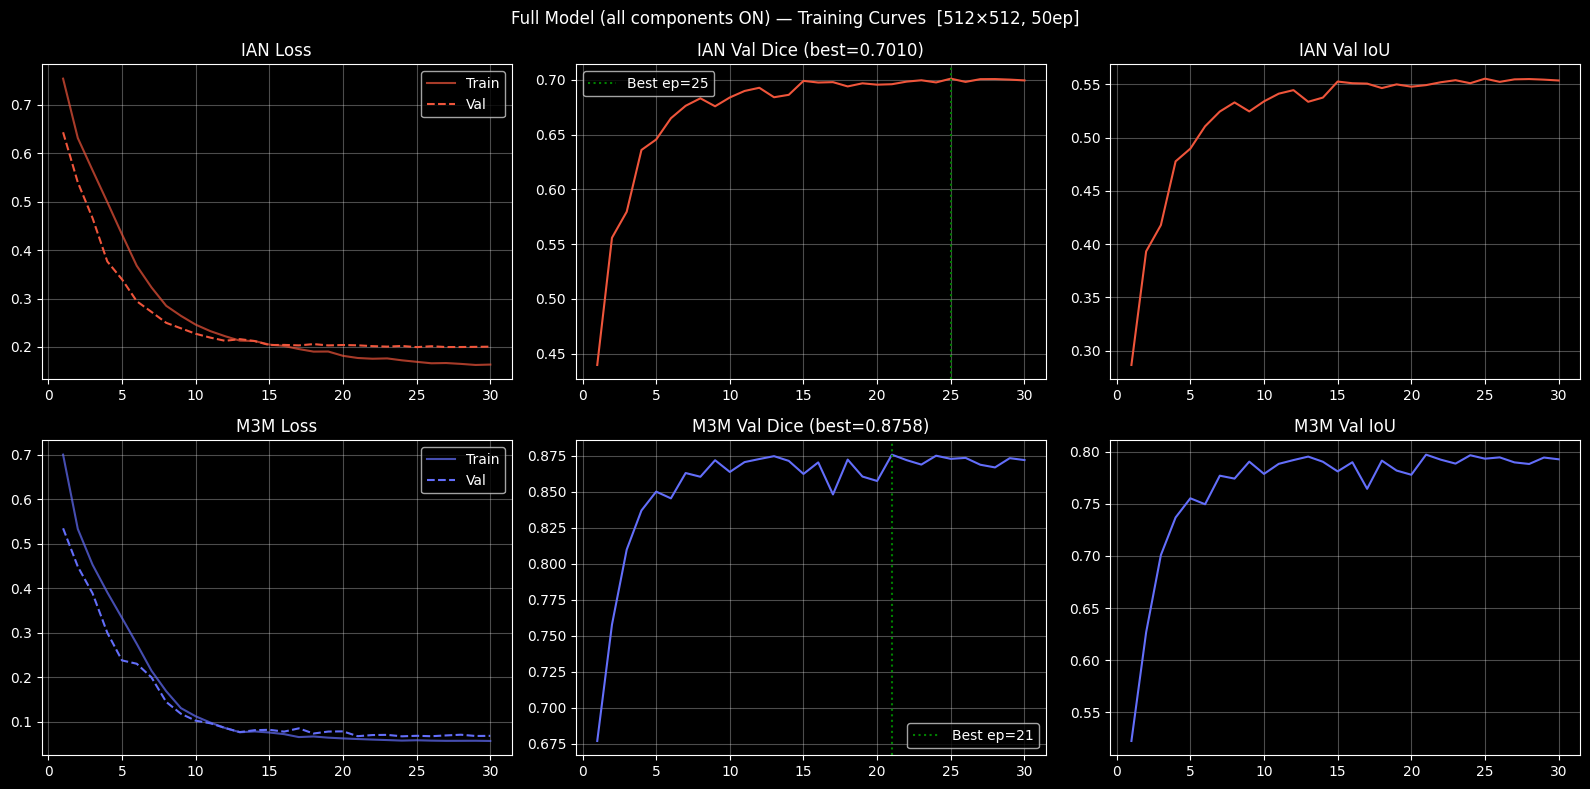

C:\Users\minud\AppData\Local\Temp\ipykernel_25608\4082333387.py:65: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ian_model.load_state_dict(torch.load(ian_best, map_location


  Results — Full Model (all components ON)
    IAN: Dice=0.6838  IoU=0.5356  Precision=0.6740  Recall=0.7154  mAP50=0.9818  mAP50-95=0.4637
    M3M: Dice=0.8759  IoU=0.7898  Precision=0.8816  Recall=0.8871  mAP50=1.0000  mAP50-95=1.0000

#################################################################
  Remove Preprocessing  ← REMOVED: Preprocessing
  preprocess  : raw (OFF)
  IAN loss    : DiceBCELoss(dice_weight=0.6)
  M3M loss    : DiceBCELoss(dice_weight=0.4)
  aug         : Full pipeline
#################################################################

Training: remove_preprocess_ian | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.6902→0.5886 | Dice 0.5444 | IoU 0.3825  ✓
  Ep  5/30 | loss 0.3007→0.2851 | Dice 0.6113 | IoU 0.4523
  Ep 10/30 | loss 0.2311→0.2184 | Dice 0.6777 | IoU 0.5271
  Ep 15/30 | loss 0.2148→0.2029 | Dice 0.6969 | IoU 0.5493  ✓
  Ep 20/30 | loss 0.1960→0.2028 | Dice 0.6956 | IoU 0.5474
  Ep 25/30 | loss 0.1799→0.2043 | Dice 0.6926 | IoU 0.5444
  Ep 30/30 | loss

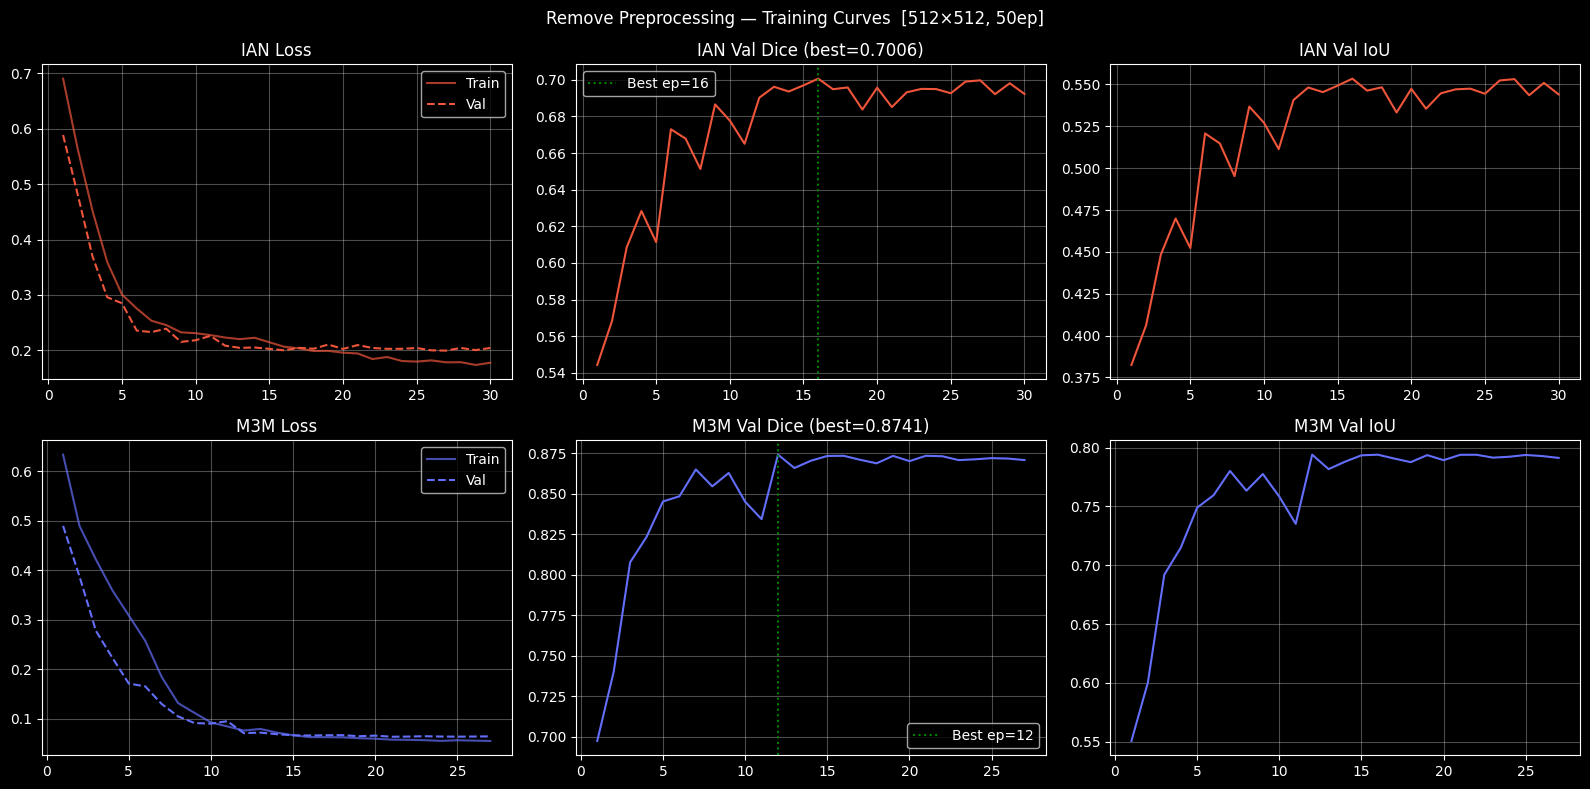

Eval remove_preprocess/M3M: 100%|██████████| 37/37 [00:05<00:00,  6.66it/s]



  Results — Remove Preprocessing
    IAN: Dice=0.6801  IoU=0.5311  Precision=0.6454  Recall=0.7415  mAP50=0.9808  mAP50-95=0.4499
    M3M: Dice=0.8783  IoU=0.7919  Precision=0.8830  Recall=0.8872  mAP50=1.0000  mAP50-95=1.0000

#################################################################
  Remove Loss (→ pure BCE)  ← REMOVED: Loss (Dice component)
  preprocess  : surgical_clahe_unsharp
  IAN loss    : DiceBCELoss(dice_weight=0.0)
  M3M loss    : DiceBCELoss(dice_weight=0.0)
  aug         : Full pipeline
#################################################################

Training: remove_loss_ian | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.4186→0.5510 | Dice 0.0002 | IoU 0.0001  ✓
  Ep  5/30 | loss 0.0626→0.0560 | Dice 0.5308 | IoU 0.3717
  Ep 10/30 | loss 0.0298→0.0279 | Dice 0.6331 | IoU 0.4743
  Ep 15/30 | loss 0.0230→0.0245 | Dice 0.6571 | IoU 0.5028
  Ep 20/30 | loss 0.0194→0.0226 | Dice 0.6785 | IoU 0.5285  ✓
  Ep 25/30 | loss 0.0173→0.0230 | Dice 0.6615 | IoU 0.5092
  Ep 30/

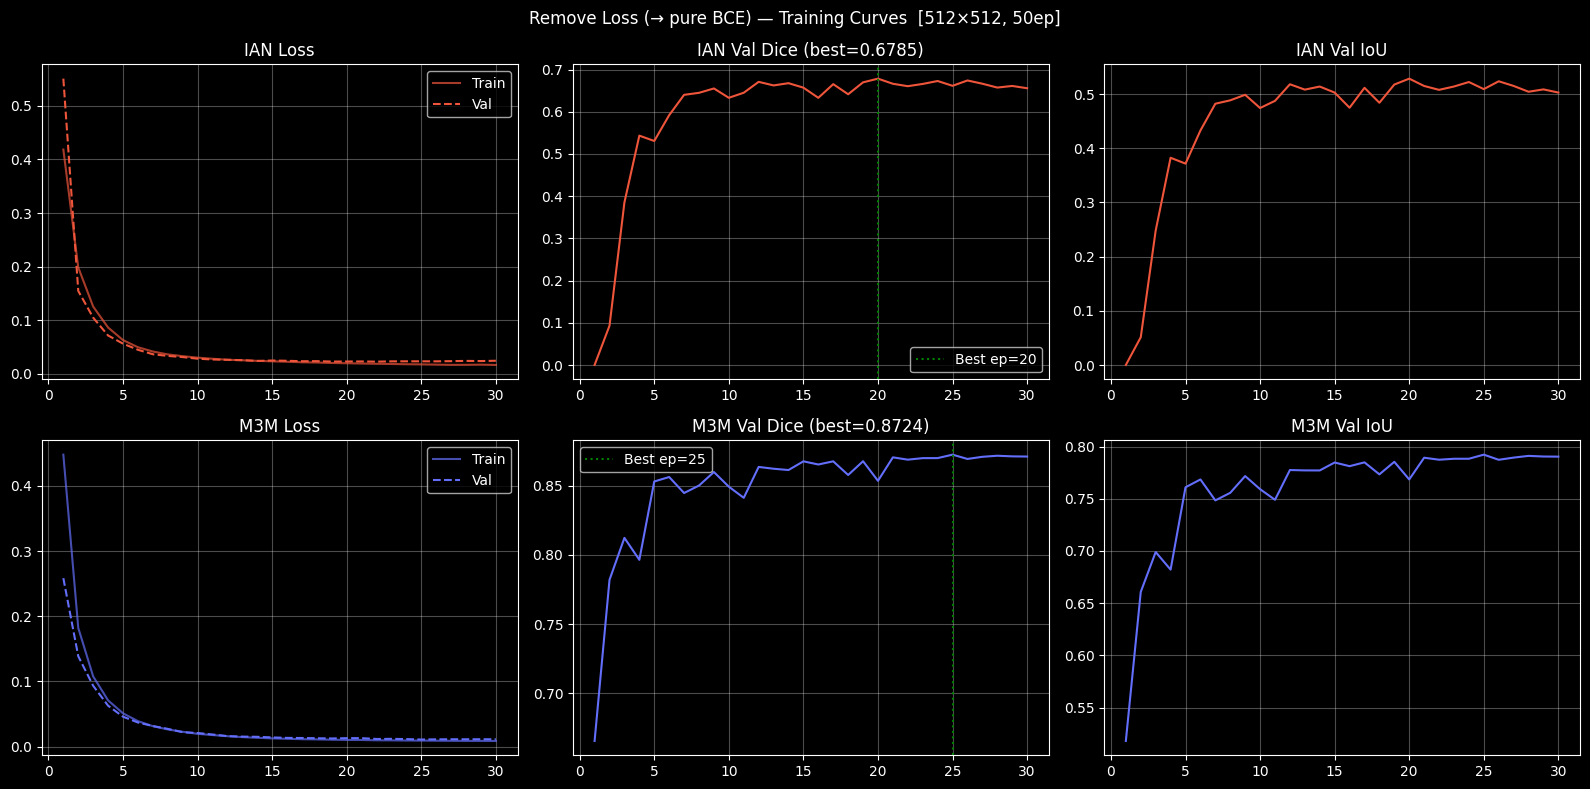

Eval remove_loss/M3M: 100%|██████████| 37/37 [00:10<00:00,  3.56it/s]



  Results — Remove Loss (→ pure BCE)
    IAN: Dice=0.6689  IoU=0.5179  Precision=0.6619  Recall=0.6948  mAP50=0.9796  mAP50-95=0.4562
    M3M: Dice=0.8842  IoU=0.7996  Precision=0.9089  Recall=0.8716  mAP50=1.0000  mAP50-95=1.0000

#################################################################
  Remove Augmentation  ← REMOVED: Augmentation
  preprocess  : surgical_clahe_unsharp
  IAN loss    : DiceBCELoss(dice_weight=0.6)
  M3M loss    : DiceBCELoss(dice_weight=0.4)
  aug         : Normalize only (OFF)
#################################################################

Training: remove_augmentation_ian | 30 epochs | lr=0.0001
  Ep  1/30 | loss 0.7243→0.6390 | Dice 0.5289 | IoU 0.3667  ✓
  Ep  5/30 | loss 0.2660→0.2689 | Dice 0.6671 | IoU 0.5152  ✓
  Ep 10/30 | loss 0.1222→0.2295 | Dice 0.6616 | IoU 0.5076
  Ep 15/30 | loss 0.0796→0.2301 | Dice 0.6595 | IoU 0.5049
  Ep 20/30 | loss 0.0583→0.2318 | Dice 0.6581 | IoU 0.5035
  Early stop @ epoch 21  (best Dice=0.6811)
  Best val Dice: 0

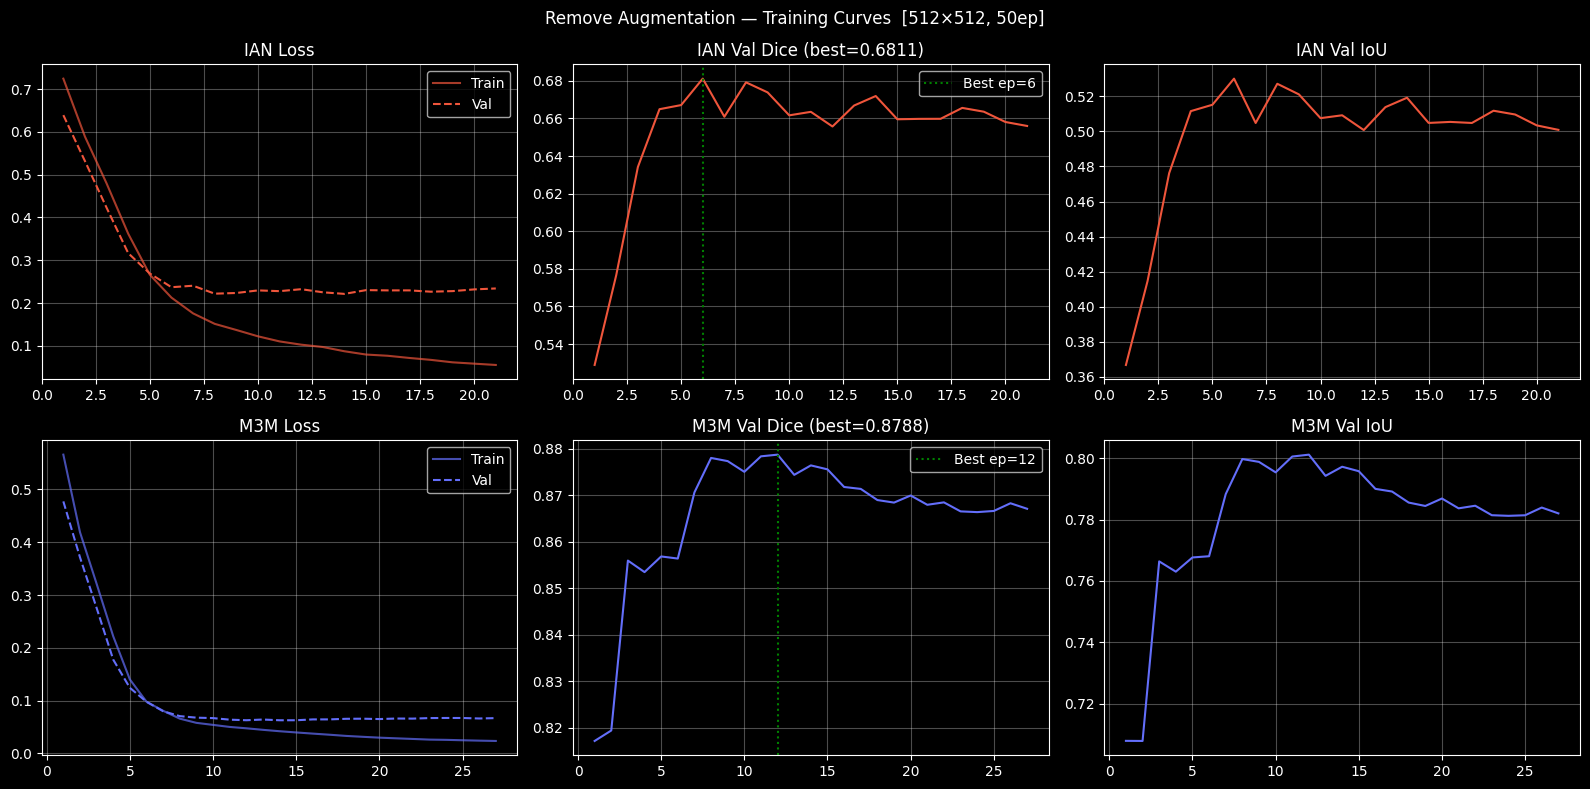

Eval remove_augmentation/M3M: 100%|██████████| 37/37 [00:10<00:00,  3.54it/s]



  Results — Remove Augmentation
    IAN: Dice=0.6554  IoU=0.5022  Precision=0.6233  Recall=0.7142  mAP50=0.9773  mAP50-95=0.4417
    M3M: Dice=0.8753  IoU=0.7884  Precision=0.8894  Recall=0.8739  mAP50=1.0000  mAP50-95=1.0000

✓ All runs complete (or skipped)


In [9]:
SKIP_RUNS   = []
all_results = {}

for cfg in ABLATION_RUNS:
    run_id  = cfg['id']; label = cfg['label']
    run_dir = os.path.join(ABLATION_DIR, run_id)
    os.makedirs(run_dir, exist_ok=True)

    if run_id in SKIP_RUNS:
        print(f'⏭  Skipping {label}'); continue

    removed_str = f'  ← REMOVED: {cfg["removed"]}' if cfg['removed'] != 'none' else '  ← FULL MODEL'
    print(f'\n{"#"*65}')
    print(f'  {label}{removed_str}')
    print(f'  preprocess  : {"surgical_clahe_unsharp" if cfg["preprocess"].__name__ != "no_preprocessing" else "raw (OFF)"}')
    print(f'  IAN loss    : DiceBCELoss(dice_weight={cfg["ian_dice_w"]})')
    print(f'  M3M loss    : DiceBCELoss(dice_weight={cfg["m3m_dice_w"]})')
    print(f'  aug         : {"Full pipeline" if cfg["train_tfm"] is AUGMENTATION_ON else "Normalize only (OFF)"}')
    print(f'{"#"*65}')

    # Datasets
    train_ds = DentalDataset(SPLITS['train'], IMAGE_DIR, img_to_anns, IAN_CAT_ID, M3M_CAT_ID,
                              cfg['train_tfm'], cfg['preprocess'])
    val_ds   = DentalDataset(SPLITS['val'],   IMAGE_DIR, img_to_anns, IAN_CAT_ID, M3M_CAT_ID,
                              VAL_TRANSFORM,   cfg['preprocess'])
    test_ds  = DentalDataset(SPLITS['test'],  IMAGE_DIR, img_to_anns, IAN_CAT_ID, M3M_CAT_ID,
                              VAL_TRANSFORM,   cfg['preprocess'])

    train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=False)
    val_loader   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)
    test_loader  = DataLoader(test_ds,  BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=False)

    ian_criterion = DiceBCELoss(dice_weight=cfg['ian_dice_w'])
    m3m_criterion = DiceBCELoss(dice_weight=cfg['m3m_dice_w'])

    # Train
    ian_model = build_unet().to(DEVICE)
    ian_history, ian_best = train_one_model(ian_model, ian_criterion, train_loader, val_loader,
                                             f'{run_id}_ian', run_dir, mask_idx=0)
    m3m_model = build_unet().to(DEVICE)
    m3m_history, m3m_best = train_one_model(m3m_model, m3m_criterion, train_loader, val_loader,
                                             f'{run_id}_m3m', run_dir, mask_idx=1)

    # Training curves
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    fig.suptitle(f'{label} — Training Curves  [512×512, 50ep]', fontsize=12)
    for hist, lbl, col, row in [(ian_history,'IAN','#EF553B',axes[0]),
                                 (m3m_history,'M3M','#636EFA',axes[1])]:
        eps = range(1, len(hist['val_dice'])+1)
        row[0].plot(eps, hist['train_loss'], color=col, alpha=0.7, label='Train')
        row[0].plot(eps, hist['val_loss'],   color=col, ls='--', label='Val')
        row[0].set_title(f'{lbl} Loss'); row[0].legend(); row[0].grid(alpha=0.3)
        best_ep = np.argmax(hist['val_dice'])+1
        row[1].plot(eps, hist['val_dice'], color=col)
        row[1].axvline(best_ep, color='green', ls=':', label=f'Best ep={best_ep}')
        row[1].set_title(f'{lbl} Val Dice (best={max(hist["val_dice"]):.4f})')
        row[1].legend(); row[1].grid(alpha=0.3)
        row[2].plot(eps, hist['val_iou'], color=col)
        row[2].set_title(f'{lbl} Val IoU'); row[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(run_dir, 'training_curves.png'), dpi=120, bbox_inches='tight')
    plt.show()

    # Evaluate
    ian_model.load_state_dict(torch.load(ian_best, map_location='cpu')); ian_model.to(DEVICE)
    m3m_model.load_state_dict(torch.load(m3m_best, map_location='cpu')); m3m_model.to(DEVICE)
    ian_metrics = full_evaluation(ian_model, test_loader, 0, f'{run_id}/IAN')
    m3m_metrics = full_evaluation(m3m_model, test_loader, 1, f'{run_id}/M3M')
    all_results[run_id] = {'label': label, 'removed': cfg['removed'],
                            'IAN': ian_metrics, 'M3M': m3m_metrics}

    print(f'\n  Results — {label}')
    for cls, m in [('IAN', ian_metrics), ('M3M', m3m_metrics)]:
        print(f'    {cls}: ' + '  '.join(f'{k}={v:.4f}' for k,v in m.items()))

    with open(os.path.join(run_dir, 'test_metrics.json'), 'w') as f:
        json.dump({
            'run': run_id, 'label': label, 'removed': cfg['removed'],
            'img_size': IMG_SIZE, 'epochs': EPOCHS,
            'config': {'preprocess': cfg['preprocess'].__name__,
                       'ian_dice_weight': cfg['ian_dice_w'],
                       'm3m_dice_weight': cfg['m3m_dice_w'],
                       'augmentation': 'ON' if cfg['train_tfm'] is AUGMENTATION_ON else 'OFF'},
            'IAN': {k: round(v,4) for k,v in ian_metrics.items()},
            'M3M': {k: round(v,4) for k,v in m3m_metrics.items()},
        }, f, indent=2)

print('\n✓ All runs complete (or skipped)')


## 10. Load Metrics for Skipped Runs

In [10]:
for cfg in ABLATION_RUNS:
    run_id = cfg['id']
    if run_id not in SKIP_RUNS: continue
    path = os.path.join(ABLATION_DIR, run_id, 'test_metrics.json')
    if not os.path.exists(path):
        print(f'⚠️  No saved metrics at {path}'); continue
    with open(path) as f: saved = json.load(f)
    all_results[run_id] = {'label': saved.get('label', cfg['label']),
                            'removed': saved.get('removed', cfg['removed']),
                            'IAN': saved['IAN'], 'M3M': saved['M3M']}
    print(f'✓ Loaded {run_id}: IAN mAP50-95={saved["IAN"]["mAP50-95"]:.4f}')

print(f'Results available: {list(all_results.keys())}')


Results available: ['full', 'remove_preprocess', 'remove_loss', 'remove_augmentation']


## 11. Results Table

In [11]:
RUN_ORDER = ['full', 'remove_preprocess', 'remove_loss', 'remove_augmentation']
rows = []
full_ian = all_results.get('full', {}).get('IAN', {})

for run_id in RUN_ORDER:
    if run_id not in all_results:
        print(f'⚠️  {run_id} missing'); continue
    res = all_results[run_id]
    ian = res['IAN']
    drop_map = round(full_ian.get('mAP50-95', 0) - ian['mAP50-95'], 4) if run_id != 'full' else '—'
    drop_dice = round(full_ian.get('Dice', 0) - ian['Dice'], 4) if run_id != 'full' else '—'
    rows.append({
        'Run':              res['label'],
        'IAN mAP50-95':    round(ian['mAP50-95'], 4),
        'Δ mAP50-95':      drop_map,
        'IAN Dice':        round(ian['Dice'], 4),
        'Δ Dice':          drop_dice,
        'IAN mAP50':       round(ian['mAP50'], 4),
        'M3M mAP50-95':   round(res['M3M']['mAP50-95'], 4),
        'M3M Dice':        round(res['M3M']['Dice'], 4),
    })

df = pd.DataFrame(rows)
print('\n' + '='*100)
print('SUBTRACT-ONE-OUT ABLATION — 512×512 — TEST SET RESULTS')
print('(Δ = Full model score minus this run — larger drop = component more important)')
print('='*100)
print(df.to_string(index=False))
print('='*100)

df.to_csv(os.path.join(ABLATION_DIR, 'ablation_results.csv'), index=False)
print(f'\n✓ Saved: {ABLATION_DIR}')



SUBTRACT-ONE-OUT ABLATION — 512×512 — TEST SET RESULTS
(Δ = Full model score minus this run — larger drop = component more important)
                           Run  IAN mAP50-95 Δ mAP50-95  IAN Dice  Δ Dice  IAN mAP50  M3M mAP50-95  M3M Dice
Full Model (all components ON)        0.4637          —    0.6838       —     0.9818           1.0    0.8759
          Remove Preprocessing        0.4499     0.0137    0.6801  0.0037     0.9808           1.0    0.8783
      Remove Loss (→ pure BCE)        0.4562     0.0074    0.6689   0.015     0.9796           1.0    0.8842
           Remove Augmentation        0.4417      0.022    0.6554  0.0284     0.9773           1.0    0.8753

✓ Saved: E:\IIT\NEW_FYP\MODELS\Ablation_Subtract_One_Out


## 12. Visual Comparison

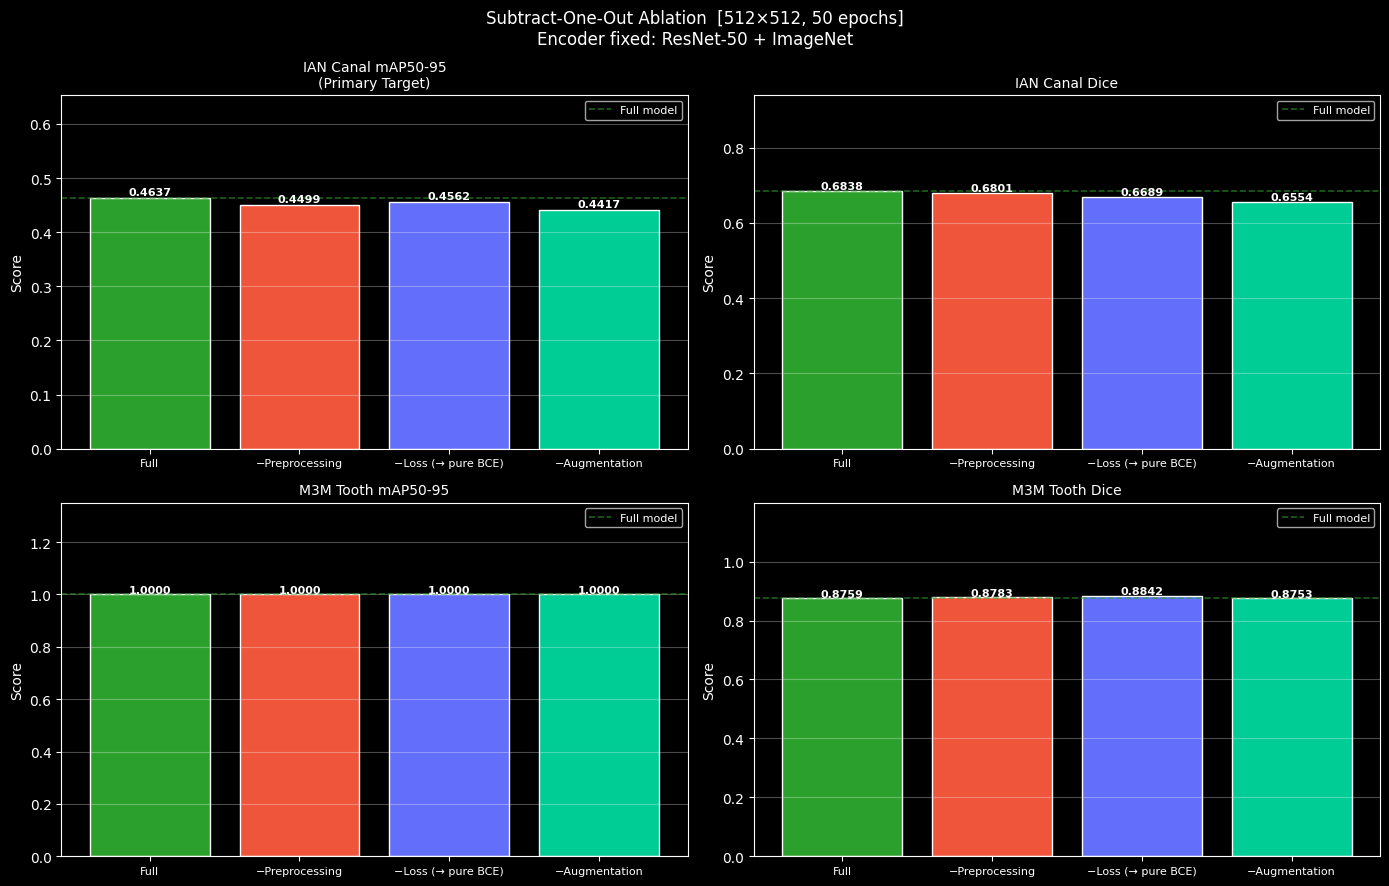

✓ Chart saved


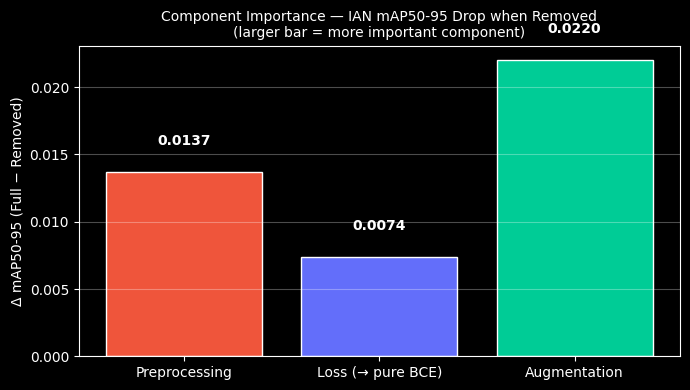

✓ Component importance chart saved


In [12]:
if len(rows) < 2:
    print('Not enough results to plot yet.')
else:
    run_labels = [r['Run'].replace('Remove ', '−').replace('Full Model (all components ON)', 'Full') for r in rows]
    colors     = ['#2CA02C', '#EF553B', '#636EFA', '#00CC96']  # green=full, then removes

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle('Subtract-One-Out Ablation  [512×512, 50 epochs]\n'
                 'Encoder fixed: ResNet-50 + ImageNet', fontsize=12)

    metrics_to_plot = [
        ('IAN mAP50-95', 'IAN Canal mAP50-95\n(Primary Target)'),
        ('IAN Dice',     'IAN Canal Dice'),
        ('M3M mAP50-95', 'M3M Tooth mAP50-95'),
        ('M3M Dice',     'M3M Tooth Dice'),
    ]

    for ax, (col, title) in zip(axes.flat, metrics_to_plot):
        vals = [r[col] for r in rows]
        bars = ax.bar(run_labels, vals, color=colors[:len(vals)], edgecolor='white')
        # Draw a dashed line at the full model score for easy visual comparison
        full_val = vals[0]
        ax.axhline(full_val, color='#2CA02C', linestyle='--', linewidth=1.2, alpha=0.6, label='Full model')
        ax.set_title(title, fontsize=10)
        ax.set_ylim(0, max(vals)*1.3+0.05)
        ax.set_ylabel('Score'); ax.tick_params(axis='x', labelsize=8); ax.grid(axis='y', alpha=0.3)
        ax.legend(fontsize=8)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                    f'{v:.4f}', ha='center', fontsize=8, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(ABLATION_DIR, 'ablation_comparison.png'), dpi=140, bbox_inches='tight')
    plt.show()
    print('✓ Chart saved')

# ── Δ drop chart (IAN mAP50-95 only) ─────────────────────────────────────────
if len(rows) > 1:
    remove_rows  = [r for r in rows if r['Run'] != 'Full Model (all components ON)']
    remove_labels = [r['Run'].replace('Remove ', '') for r in remove_rows]
    drops = [r['Δ mAP50-95'] for r in remove_rows]
    drop_colors = ['#EF553B', '#636EFA', '#00CC96']

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(remove_labels, drops, color=drop_colors[:len(drops)], edgecolor='white')
    ax.set_title('Component Importance — IAN mAP50-95 Drop when Removed\n'
                 '(larger bar = more important component)', fontsize=10)
    ax.set_ylabel('Δ mAP50-95 (Full − Removed)')
    ax.grid(axis='y', alpha=0.3)
    for bar, v in zip(bars, drops):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                f'{v:.4f}', ha='center', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(ABLATION_DIR, 'component_importance.png'), dpi=140, bbox_inches='tight')
    plt.show()
    print('✓ Component importance chart saved')


## 13. Cross-Study Comparison

Optional: paste your isolate-one-only results here to compare both studies side by side.

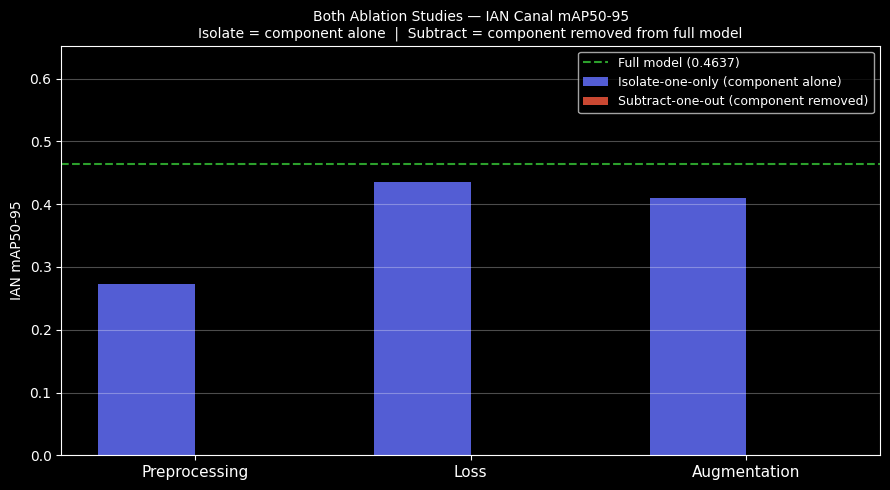

✓ Cross-study comparison chart saved


In [13]:
# Paste isolate-one-only results from the v3 lite notebook here
# (IAN mAP50-95 values only for the primary target metric)
isolate_results = {
    'Isolate Preprocessing': 0.2733,   # ← update from your v3 lite run
    'Isolate Loss':          0.4348,   # ← update from your v3 lite run
    'Isolate Augmentation':  0.4103,   # ← update from your v3 lite run
}

subtract_results = {
    r['Run'].replace('Remove ', ''): r['IAN mAP50-95']
    for r in rows if r['Run'] != 'Full Model (all components ON)'
}
full_score = next((r['IAN mAP50-95'] for r in rows if r['Run'] == 'Full Model (all components ON)'), None)

if subtract_results and full_score is not None:
    components = ['Preprocessing', 'Loss', 'Augmentation']
    iso_vals  = [isolate_results.get(f'Isolate {c}', 0) for c in components]
    sub_vals  = [subtract_results.get(f'Remove {c}', subtract_results.get(f'Remove {c} (→ pure BCE)', 0))
                 for c in components]

    x = np.arange(len(components)); width = 0.35
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(x - width/2, iso_vals, width, label='Isolate-one-only (component alone)', color='#636EFA', alpha=0.85)
    ax.bar(x + width/2, sub_vals, width, label='Subtract-one-out (component removed)', color='#EF553B', alpha=0.85)
    ax.axhline(full_score, color='#2CA02C', linestyle='--', linewidth=1.5, label=f'Full model ({full_score:.4f})')
    ax.set_xticks(x); ax.set_xticklabels(components, fontsize=11)
    ax.set_ylabel('IAN mAP50-95'); ax.set_ylim(0, max(max(iso_vals), max(sub_vals), full_score)*1.3+0.05)
    ax.set_title('Both Ablation Studies — IAN Canal mAP50-95\n'
                 'Isolate = component alone  |  Subtract = component removed from full model', fontsize=10)
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(ABLATION_DIR, 'cross_study_comparison.png'), dpi=140, bbox_inches='tight')
    plt.show()
    print('✓ Cross-study comparison chart saved')


## 14. How to Interpret the Results

**Reading subtract-one-out results:**  
The Δ column shows how much IAN mAP50-95 drops when each component is removed from the full model.  
A large drop means the model relies heavily on that component — the other two components cannot compensate for its absence.

**Combining with isolate-one-only (from v3 lite):**  
Cross-referencing both studies gives a fuller picture:

- A component that **scores high in isolation AND causes a large drop when removed** is independently powerful and non-redundant — the strongest case for inclusion.
- A component that **scores low in isolation BUT causes a large drop when removed** only works in combination with the others (synergistic) — still important, but dependent.
- A component that **scores high in isolation BUT causes a small drop when removed** overlaps with other components — its contribution is partially redundant.
- A component that **scores low in both** is a weak contributor overall.

Use the cross-study chart in Section 13 to visualise all four cases at once.
